# Week 5: Correlation & Regression

**Contents**

0. Setup and data
1. Correlation: what it is, covariance, Pearson's r, the coefficient of determination, when we can use it, testing and comparing correlations, correlation is not causation
2. Linear regression: what it is, the method of least squares, interpretation, explained variance, standard errors and confidence intervals, assumptions
3. Summary

The two variables that run through the notebook are **`Age`** (years) and **`nWBV`** (normalized whole-brain volume, the share of the intracranial volume that is brain tissue). Brain volume shrinks with age, so we expect a clear negative relationship.

## 0. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)          # seed: results are reproducible

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
C1, C2, GREY = "#0072B2", "#D55E00", "#6b6b6b"   # colour-blind-safe blue / orange

df = pd.read_csv("oasis_cross-sectional_MR1.csv")
assert len(df) == 416
age  = df["Age"].to_numpy(float)
nwbv = df["nWBV"].to_numpy(float)
etiv = df["eTIV"].to_numpy(float)
df[["Age", "nWBV", "eTIV"]].describe().round(3)

Matplotlib is building the font cache; this may take a moment.


,Age,nWBV,eTIV
count,416.000,416.000,416.000
mean,52.702,0.789,1480.526
std,25.082,0.060,158.344
min,18.000,0.644,1123.000
25%,24.000,0.740,1366.750
50%,56.000,0.804,1475.000
75%,75.000,0.841,1578.000
max,96.000,0.893,1992.000


`Age`, `nWBV` and `eTIV` have no missing values, so all 416 participants enter the analysis.

## 1. Correlation

### 1.1 What is a correlation?

A correlation measures the strength and direction of the **(linear) relationship between two variables**:

* **positive:** high values in one variable go along with high values in the other (the order of the values is mostly the same);
* **negative:** high values in one variable go along with low values in the other (the order is mostly opposite);
* **none:** knowing one variable tells us nothing (linear) about the other.

The standard picture is the **scatter plot**: one dot per person, the first variable on the x-axis, the second on the y-axis. Here are one negative and one "no relationship" example from the data:

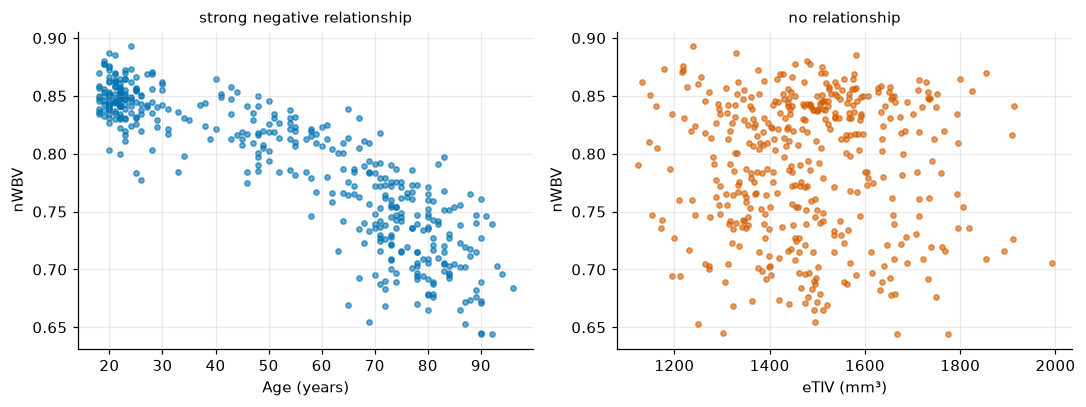

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(age, nwbv, s=12, color=C1, alpha=.6)
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("nWBV")
axes[0].set_title("strong negative relationship", fontsize=10)
axes[1].scatter(etiv, nwbv, s=12, color=C2, alpha=.6)
axes[1].set_xlabel("eTIV (mm³)"); axes[1].set_ylabel("nWBV")
axes[1].set_title("no relationship", fontsize=10)
plt.tight_layout()
plt.show()

Left: the older the participant, the lower the brain volume, and the dots follow a clear downward trend. Right: head size (`eTIV`) says nothing about the *normalized* brain volume (`nWBV` is already divided by the head size, so this is what we expect): the cloud has no direction.

### 1.2 Covariance

The **covariance** measures how two variables vary *together*: for each person we multiply the deviation of x from its mean with the deviation of y from its mean, and average these products (dividing by N − 1, like the variance):

$$cov_{xy} = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{N - 1}$$

If a person is above average in both variables (or below average in both), the product is positive. If above in one and below in the other, it is negative. The sign of the sum tells us the direction of the relationship.

In [3]:
n = len(df)
dx = age - age.mean()                    # deviation of every person's age from the mean age
dy = nwbv - nwbv.mean()                  # the same for nWBV
products = dx * dy                       # one product per person

cov_xy = products.sum() / (n - 1)
print(f"covariance by hand : {cov_xy:.4f}")
print(f"np.cov             : {np.cov(age, nwbv)[0, 1]:.4f}")
print(f"share of persons with a positive product: {(products > 0).mean():.2f}")

covariance by hand : -1.3159
np.cov             : -1.3159
share of persons with a positive product: 0.11


The covariance is negative (older persons have a lower `nWBV`), and in about nine out of ten persons (89%) the two deviations point in *opposite* directions. But **how strong** is it? The number depends on the units of the variables: it is measured in "years × nWBV units". If we measured age in months, the covariance would be twelve times as large, while the relationship is exactly the same. That is why we standardize.

In [4]:
cov_months = np.cov(age * 12, nwbv)[0, 1]
print(f"covariance with age in years : {cov_xy:.3f}")
print(f"covariance with age in months: {cov_months:.3f}   (x12, same relationship)")

covariance with age in years : -1.316
covariance with age in months: -15.791   (x12, same relationship)


### 1.3 Pearson's correlation coefficient

Pearson's **r** divides the covariance by the **product of the two standard deviations**, which removes the units:

$$r_{xy} = \frac{cov_{xy}}{s_x \cdot s_y} = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{(N-1)\, s_x s_y}$$

Equivalently: *the correlation is the covariance of the z-standardized values* (the z-scores from week 3). It always lies between **−1** (perfect negative linear relationship) and **+1** (perfect positive), with values around 0 meaning no linear relationship.

In [5]:
sx, sy = age.std(ddof=1), nwbv.std(ddof=1)
r_hand = cov_xy / (sx * sy)

zx = (age - age.mean()) / sx             # z-standardize both variables
zy = (nwbv - nwbv.mean()) / sy
r_z = np.cov(zx, zy)[0, 1]               # covariance of the z-scores

r_scipy, p_scipy = stats.pearsonr(age, nwbv)
print(f"r = cov / (sx * sy)      : {r_hand:.4f}")
print(f"r = cov of the z-scores  : {r_z:.4f}")
print(f"scipy.stats.pearsonr     : {r_scipy:.4f}")
print(f"r with age in months     : {stats.pearsonr(age * 12, nwbv)[0]:.4f}   (unchanged)")
print(f"r(eTIV, nWBV) = {stats.pearsonr(etiv, nwbv)[0]:.3f}  (the 'no relationship' plot)")

r = cov / (sx * sy)      : -0.8728
r = cov of the z-scores  : -0.8728
scipy.stats.pearsonr     : -0.8728
r with age in months     : -0.8728   (unchanged)
r(eTIV, nWBV) = -0.009  (the 'no relationship' plot)


Three routes, one number: **r = −0.87**, a strong negative correlation. Changing the unit of age (years to months) does not change r. For the "no relationship" plot, r is practically 0.

**Rules of thumb** (as for Cohen's d, these are guides, not laws): |r| around .1 is small, around .3 medium, above .5 large. Always look at the scatter plot as well, because very different pictures can give the same r (see 1.5).

### 1.4 The coefficient of determination, r²

Squaring the correlation gives the **coefficient of determination r²**: the **share of the variance that the two variables have in common** ("shared" or "overlapping" variance). It ranges from 0 to 1 (0% to 100%). In words: *how much of the variance of one variable is explained by the other?* The relationship is symmetric: it does not matter which variable we call x and which y.

In [6]:
r2 = r_hand ** 2
print(f"r = {r_hand:.3f}  ->  r² = {r2:.3f}")
print(f"{r2:.0%} of the variance of nWBV is shared with Age; {1 - r2:.0%} is not.")
print(f"for comparison, r(eTIV, nWBV)² = {stats.pearsonr(etiv, nwbv)[0]**2:.5f}")

r = -0.873  ->  r² = 0.762
76% of the variance of nWBV is shared with Age; 24% is not.
for comparison, r(eTIV, nWBV)² = 0.00008


Age and brain volume share about three quarters of their variance. The remaining quarter is everything else that makes brain volumes differ between people of the same age: genetics, health, education, measurement noise, and more. Note that r = −.87 sounds "almost perfect", but r² = .76 reminds us that a quarter of the variance is still unexplained.

### 1.5 When can I use a correlation?

The slides name three conditions:

1. **Equal-interval scale** (and approximately normally distributed data, strictly: a bivariate normal distribution, which matters for the significance test in 1.6).
2. **Only linear relationships:** r measures how well the points follow a *straight line*. A perfect curved relationship can have a small r.
3. **Homoscedasticity:** the spread of y should be about the same at every value of x (the slides call this "high homoskedasticity"). If the spread grows with x, the single number r describes the cloud poorly.

Our data give an instructive case for conditions 1 and 3: the **MMSE** (cognitive screening score, 0 to 30) against `Age`. MMSE is only available for the participants with a clinical rating (n = 235).

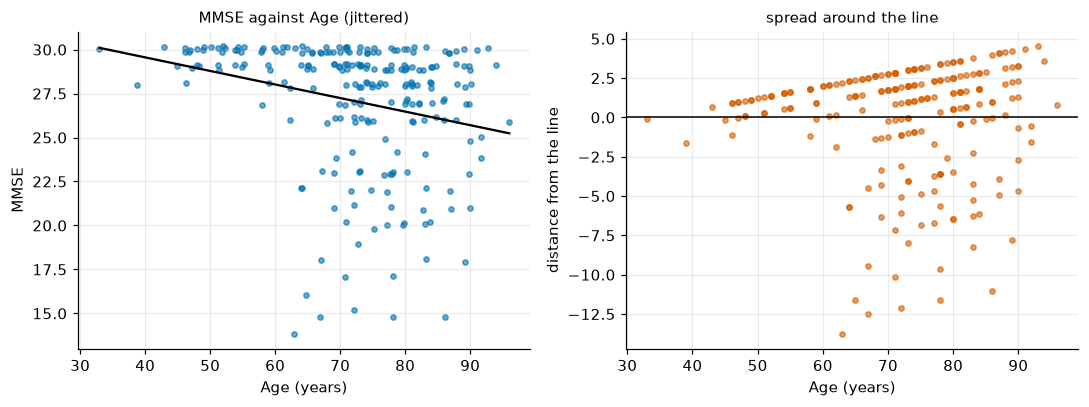

        n  SD around the line
< 60   39                0.87
60-69  45                4.38
70-79  90                3.83
80+    61                3.52

Pearson r = -0.252 | Spearman rho = -0.340


In [7]:
m = df["MMSE"].notna()
a_m, mm = df.loc[m, "Age"].to_numpy(float), df.loc[m, "MMSE"].to_numpy(float)
lr_m = stats.linregress(a_m, mm)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(a_m + rng.uniform(-.3, .3, len(a_m)), mm + rng.uniform(-.2, .2, len(mm)),
                s=12, color=C1, alpha=.6)               # a little jitter: many identical scores
xx = np.array([a_m.min(), a_m.max()])
axes[0].plot(xx, lr_m.intercept + lr_m.slope * xx, color="black", lw=1.5)
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("MMSE")
axes[0].set_title("MMSE against Age (jittered)", fontsize=10)

resid_m = mm - (lr_m.intercept + lr_m.slope * a_m)
axes[1].scatter(a_m, resid_m, s=12, color=C2, alpha=.6)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Age (years)"); axes[1].set_ylabel("distance from the line")
axes[1].set_title("spread around the line", fontsize=10)
plt.tight_layout()
plt.show()

bands = pd.cut(a_m, [17, 60, 70, 80, 100], labels=["< 60", "60-69", "70-79", "80+"])
print(pd.DataFrame({"n": pd.Series(resid_m).groupby(bands, observed=True).size(),
                    "SD around the line": pd.Series(resid_m).groupby(bands, observed=True).std().round(2)}))
rho = stats.spearmanr(a_m, mm)[0]
print(f"\nPearson r = {lr_m.rvalue:.3f} | Spearman rho = {rho:.3f}")

Two problems are visible:

* **Ceiling effect:** most participants score 29 or 30, so the points are squeezed against the upper limit of the scale. The MMSE is also not a true equal-interval scale (the difference between 29 and 30 is not the same as between 14 and 15 in terms of cognitive ability).
* **Unequal spread (heteroscedasticity):** below age 60 nearly everybody scores close to the maximum (small spread around the line), while above 60 some scores fall far below. The spread around the line is about four to five times larger in the older groups. A single r (here −.25) averages over very different situations.

When the scale is only ordinal, or the relationship is monotonic but not linear, the **Spearman rank correlation** is an alternative: it is Pearson's r computed on the *ranks* of the values. Here it is a bit larger (−.34), because it is less bothered by the ceiling. (We will meet rank-based methods again in the last session.)

### 1.6 Testing a correlation, and comparing two correlations

**Is a correlation different from zero?** We can test it with a *t-test* (the single-group t-test from last week, applied to r), with df = N − 2:

$$t = \frac{r\sqrt{N-2}}{\sqrt{1-r^2}}$$

H0: the true correlation in the population is 0. We can also give a **confidence interval** for r. Since correlations are *not* on an equal-interval scale (the distribution of r is skewed near ±1), the interval is built on **Fisher's z-transformation** (not the same as the z-standardization!) and back-transformed:

$$Z = \frac{1}{2}\ln\left(\frac{1+r}{1-r}\right) = \operatorname{arctanh}(r), \qquad SE_Z = \frac{1}{\sqrt{N-3}}$$

In [8]:
dof = n - 2
t_r = r_hand * np.sqrt(dof) / np.sqrt(1 - r_hand**2)
p_r = 2 * stats.t.sf(abs(t_r), dof)
print(f"t({dof}) = {t_r:.2f}, p = {p_r:.2g}   (pearsonr gives p = {p_scipy:.2g})")

z = np.arctanh(r_hand)                           # Fisher's z
se_z = 1 / np.sqrt(n - 3)
ci = np.tanh([z - 1.96 * se_z, z + 1.96 * se_z]) # back-transform the interval
print(f"95% CI for r: [{ci[0]:.3f}, {ci[1]:.3f}]")

t(414) = -36.39, p = 4.6e-131   (pearsonr gives p = 4.6e-131)
95% CI for r: [-0.894, -0.848]


The test is, as expected, hugely significant, and the interval is narrow. A tiny p-value only says that r differs from 0, not that the relationship is *strong*: that is what r and r² are for (the same lesson as for p-values and effect sizes last week). With a large sample, even r = .1 would be "significant".

**Do two correlations differ?** Two correlations from *independent* groups cannot be compared directly, because of the skewness mentioned above. So we transform both with Fisher's z, and compare the difference with its standard error (a z-test, using the normal distribution; "same logic as a t-test"):

$$z_{emp} = \frac{Z_1 - Z_2}{\sqrt{\frac{1}{N_1-3} + \frac{1}{N_2-3}}}$$

If $|z_{emp}| > z_{crit}$ (1.96 for a two-sided test at α = .05), the difference is significant. Example: is the age-brain-volume correlation different in men and women?

In [9]:
male = (df["M_F"] == "M").to_numpy()
r_m = stats.pearsonr(age[male], nwbv[male])[0]
r_f = stats.pearsonr(age[~male], nwbv[~male])[0]
n_m, n_f = male.sum(), (~male).sum()

z_emp = (np.arctanh(r_m) - np.arctanh(r_f)) / np.sqrt(1 / (n_m - 3) + 1 / (n_f - 3))
p_diff = 2 * stats.norm.sf(abs(z_emp))
print(f"men  : r = {r_m:.3f} (n = {n_m})")
print(f"women: r = {r_f:.3f} (n = {n_f})")
print(f"z_emp = {z_emp:.2f}, critical value = {stats.norm.ppf(.975):.2f}, p = {p_diff:.3f}")

men  : r = -0.905 (n = 160)
women: r = -0.860 (n = 256)
z_emp = -2.06, critical value = 1.96, p = 0.039


Both correlations are strong and negative. The difference between them is just beyond the critical value of 1.96 (|z| = 2.06, p = .039): men show a slightly *stronger* age-volume relationship in this sample. As always, a borderline result of this kind deserves caution (see the remarks on "significant" last week): the difference between −.905 and −.860 is small.

### 1.7 Correlation is not causation

A correlation says that two variables vary together, and **nothing about why**. The slides' example: people who study more tend to have better grades, but good grades could also come from previous knowledge or logical thinking, and there are still students who study a lot and get bad grades. It is a *trend*, not a causal explanation and not true for everybody.

The same caution applies to our example. Age and brain volume are strongly correlated, but OASIS-1 is a **cross-sectional** study: each person was scanned once, so we compare *different people of different ages*, not the same person getting older. We cannot conclude from r = −.87 that "an individual's brain shrinks by this much per year". Differences between generations (health, education, nutrition) are mixed into the relationship.

## 2. Linear regression

### 2.1 What is linear regression?

A correlation describes the relationship symmetrically. **Regression** goes one step further: it **predicts** a *dependent variable* y from an *independent variable* (the "predictor") x with a straight line (in **linear** regression):

$$y = a + b \cdot x$$

* **a = intercept:** the predicted y at x = 0 (where the line starts);
* **b = slope:** how much y changes if x increases by one unit.

It only makes sense if x and y are correlated (with r near 0 the best line is flat, and x does not help to predict y). Our example: **predict `nWBV` (y) from `Age` (x).**

### 2.2 The method of least squares

Many lines could be drawn through the cloud. The one we want is the line with the smallest overall error. For each person ($i$), the **residual** is the vertical distance between the observed value $y_i$ and the value $\hat y_i$ that the line predicts. Positive and negative residuals would cancel each other, so we **square** them and minimize the sum of squared residuals:

$$\min_{a,b} \sum_i (y_i - \hat y_i)^2 \qquad\text{with}\qquad \hat y_i = a + b\, x_i$$

(The slides divide by N − 1, which does not change which line is the best.) For one predictor, the solution has a closed form: $b = r \cdot s_y / s_x$ and $a = \bar y - b \bar x$.

In [10]:
b = r_hand * sy / sx                       # slope from the correlation
a = nwbv.mean() - b * age.mean()           # intercept: the line passes through the point of means

lr = stats.linregress(age, nwbv)           # the ready-made function
print(f"by hand : a = {a:.5f}, b = {b:.6f}")
print(f"linregress: a = {lr.intercept:.5f}, b = {lr.slope:.6f}")

by hand : a = 0.89950, b = -0.002092
linregress: a = 0.89950, b = -0.002092


**Try it yourself.** Before we let the computer find the best line, search for it by hand. The widget below draws a line $y = a + b\,x$ through the data for any intercept and slope you choose. The orange segments are the residuals of all 416 persons, and the legend shows the **sum of squared residuals** of your line. Move the two sliders and try to push that number as low as you can. (Needs `ipywidgets`: `pip install ipywidgets`; it works in Jupyter, not in a static preview.)

Things to try: start from the flat line (slope 0): what is the sum of squares? (It is $SS_{tot}$ from section 2.4.) Then tilt the line. What happens if the slope is right but the intercept is too high? Can you find two *different* slopes with a similar sum of squares (a trade-off with the intercept)? Tick the box to compare with the least-squares line.

In [11]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print("ipywidgets is not installed: run  pip install ipywidgets  and restart the kernel.")

ss_best = ((nwbv - (a + b * age)) ** 2).sum()          # sum of squares of the least-squares line

def draw_line(intercept, slope, show_best=False):
    pred_ = intercept + slope * age
    ss = ((nwbv - pred_) ** 2).sum()
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    ax.scatter(age, nwbv, s=10, color=GREY, alpha=.5)
    ax.vlines(age, nwbv, pred_, color=C2, alpha=.35, lw=.8)            # residuals of all persons
    xx = np.array([age.min(), age.max()])
    ax.plot(xx, intercept + slope * xx, color=C1, lw=2.2,
            label=f"your line: a = {intercept:.3f}, b = {slope:.5f}\nsum of squared residuals = {ss:.3f}")
    if show_best:
        ax.plot(xx, a + b * xx, color="black", lw=1.5, ls="--",
                label=f"least squares: a = {a:.3f}, b = {b:.5f}\nsum of squared residuals = {ss_best:.3f}")
    ax.set_ylim(0.55, 1.0)
    ax.set_xlabel("Age (years)"); ax.set_ylabel("nWBV")
    ax.legend(frameon=False, loc="upper right", fontsize=9)
    plt.show()

if HAVE_WIDGETS:
    w = widgets.interactive(
        draw_line,
        intercept=widgets.FloatSlider(value=round(nwbv.mean(), 3), min=0.5, max=1.1, step=0.005,
                                      readout_format=".3f", description="intercept a",
                                      style={"description_width": "90px"}, layout=widgets.Layout(width="480px")),
        slope=widgets.FloatSlider(value=0.0, min=-0.004, max=0.002, step=0.00005,
                                  readout_format=".5f", description="slope b",
                                  style={"description_width": "90px"}, layout=widgets.Layout(width="480px")),
        show_best=widgets.Checkbox(value=False, description="show the least-squares line"))
    display(w)

interactive(children=(FloatSlider(value=0.789, description='intercept a', layout=Layout(width='480px'), max=1.…

Why is this the best line? We can check it directly: try many slopes, let each take its best intercept (a line through the means), and compute the sum of squared residuals for each. The smallest sum belongs to the least-squares slope.

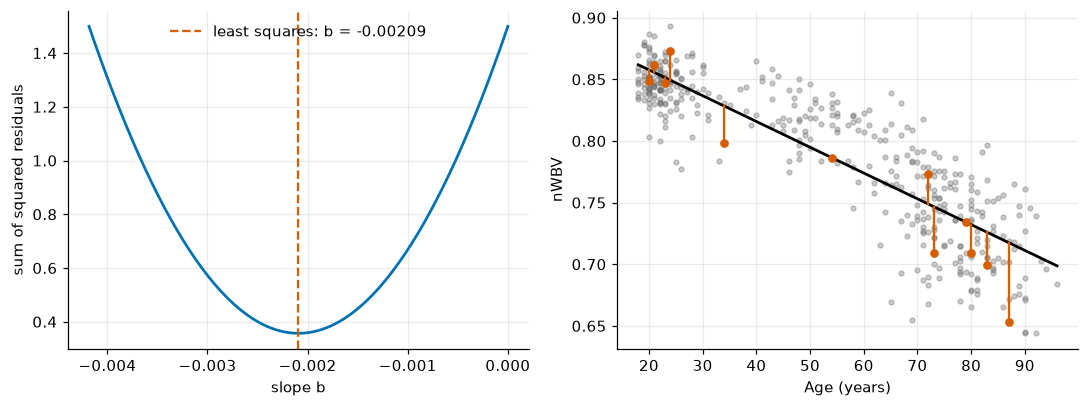

In [12]:
slopes = np.linspace(b * 2, b * 0, 201)
ss_res_curve = []
for s in slopes:
    a_s = nwbv.mean() - s * age.mean()
    ss_res_curve.append(((nwbv - (a_s + s * age)) ** 2).sum())
ss_res_curve = np.array(ss_res_curve)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(slopes, ss_res_curve, color=C1, lw=1.8)
axes[0].axvline(b, color=C2, ls="--", lw=1.5, label=f"least squares: b = {b:.5f}")
axes[0].set_xlabel("slope b"); axes[0].set_ylabel("sum of squared residuals")
axes[0].legend(frameon=False)

axes[1].scatter(age, nwbv, s=10, color=GREY, alpha=.35)
xx = np.array([age.min(), age.max()])
axes[1].plot(xx, a + b * xx, color="black", lw=1.8)
idx = rng.choice(n, 12, replace=False)                  # 12 persons with their residuals drawn in
for i in idx:
    axes[1].plot([age[i], age[i]], [nwbv[i], a + b * age[i]], color=C2, lw=1.5)
axes[1].scatter(age[idx], nwbv[idx], s=22, color=C2, zorder=3)
axes[1].set_xlabel("Age (years)"); axes[1].set_ylabel("nWBV")
plt.tight_layout()
plt.show()

Left: the sum of squares forms a bowl with its bottom exactly at the least-squares slope. Right: the regression line, and the residuals (orange segments) of 12 randomly chosen persons: the line is placed so that the *squared lengths* of all these segments (for all 416 persons) add up to as little as possible.

*A question from the slides: why do we square?* (1) Otherwise positive and negative residuals cancel and every line through the point of means would have a sum of 0. (2) Large misses are punished more than small ones. (3) The squared version has a simple closed-form solution (the absolute value does not). The price: single outliers have a strong pull on the line.

### 2.3 Interpretation: intercept, slope, prediction

In [13]:
print(f"intercept a = {a:.4f}   (predicted nWBV at Age = 0)")
print(f"slope b     = {b:.5f}  (change in nWBV per year)")
print(f"per decade  = {b * 10:.4f}")
print()
for ag in [20, 50, 70, 90]:
    print(f"predicted nWBV at age {ag}: {a + b * ag:.3f}")

intercept a = 0.8995   (predicted nWBV at Age = 0)
slope b     = -0.00209  (change in nWBV per year)
per decade  = -0.0209

predicted nWBV at age 20: 0.858
predicted nWBV at age 50: 0.795
predicted nWBV at age 70: 0.753
predicted nWBV at age 90: 0.711


* **Slope:** with each additional year of age, `nWBV` is on average **0.0021 lower** (about 0.021 per decade). The slope is in "units of y per unit of x", so its size depends on the scales of the variables, and it cannot be compared with slopes of other variables directly (see "standardized slope" below).
* **Intercept:** the prediction for age 0, which is 0.90. This is *not meaningful* here: nobody in the data is younger than 18, and a newborn's normalized brain volume is certainly not what the line says. The intercept is the anchor of the line, not always a result to interpret.
* **Predictions** are only trustworthy **inside the range of the data** (18 to 96 years). Predicting for ages far outside, say 110 or 5, is *extrapolation*: the line may no longer hold there.
* A prediction is a *mean*: at age 70 the model says 0.753, but individual people scatter around it (next section).

### 2.4 How good is the prediction? Explained variance, standard errors, confidence intervals

The quality of the predictor can be judged by how much of the variance of y it explains and how much **residual variance** is left over:

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$

$SS_{tot}$ is the total sum of squares around the mean of y (the error if we ignored x and predicted the mean for everybody). $SS_{res}$ is the sum of squared residuals around the line. In simple regression, $R^2$ equals the squared correlation.

In [14]:
pred = a + b * age
resid = nwbv - pred
ss_tot = ((nwbv - nwbv.mean()) ** 2).sum()
ss_res = (resid ** 2).sum()

print(f"SS_tot = {ss_tot:.3f}   SS_res = {ss_res:.3f}")
print(f"R² = 1 - SS_res/SS_tot = {1 - ss_res / ss_tot:.3f}   (r² = {r_hand**2:.3f})")

s_res = np.sqrt(ss_res / (n - 2))              # residual standard error (df = N - 2)
print(f"residual standard error = {s_res:.4f}  (SD of nWBV itself: {sy:.4f})")

SS_tot = 1.499   SS_res = 0.357
R² = 1 - SS_res/SS_tot = 0.762   (r² = 0.762)
residual standard error = 0.0294  (SD of nWBV itself: 0.0601)


The next figure shows what these sums are. In each panel, every segment is the distance of one person to a reference line, and the sum of the *squared* lengths is given in the legend:

* **left, $SS_{tot}$:** the distance of each person to the **mean** of `nWBV` (the best prediction if we ignore age);
* **middle, $SS_{res}$:** the distance of each person to the **regression line** (the error that remains when we use age);
* **right, $SS_{reg}$:** the distance between the regression line and the mean, the part of the variation that the line **explains** (the improvement from using age).

The three are linked: $SS_{tot} = SS_{reg} + SS_{res}$, and so $R^2 = SS_{reg}/SS_{tot} = 1 - SS_{res}/SS_{tot}$.

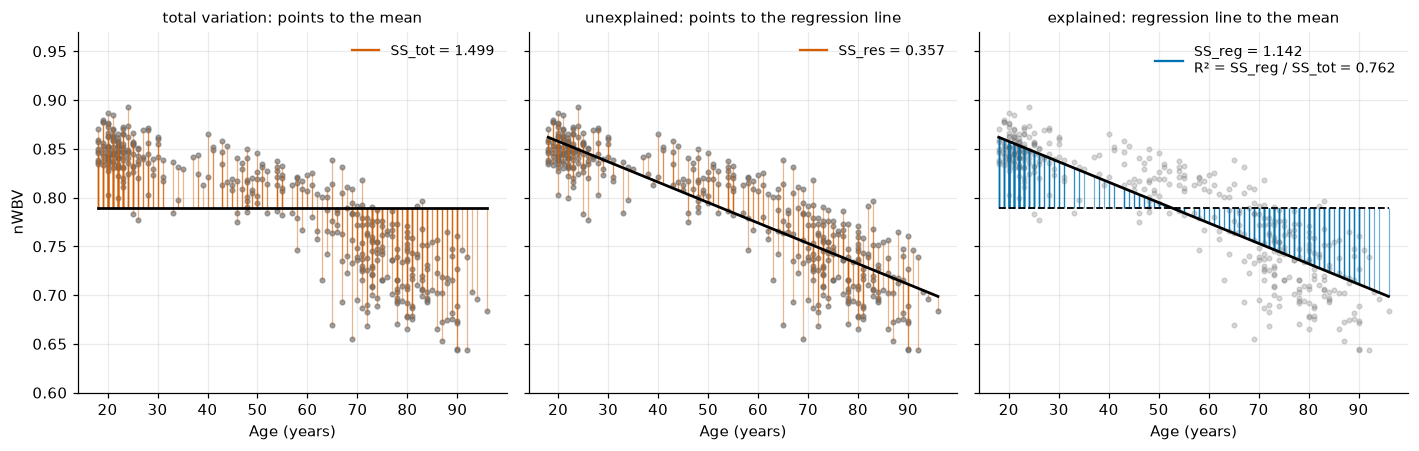

SS_reg + SS_res = 1.142 + 0.357 = 1.499   (SS_tot = 1.499)


In [15]:
ss_reg = ((pred - nwbv.mean()) ** 2).sum()                       # explained part
xx = np.array([age.min(), age.max()])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)

# left: distances to the mean -> SS_tot
ax = axes[0]
ax.scatter(age, nwbv, s=9, color=GREY, alpha=.6)
ax.vlines(age, nwbv, nwbv.mean(), color=C2, alpha=.45, lw=.8)
ax.plot(xx, [nwbv.mean()] * 2, color="black", lw=1.8)
ax.plot([], [], color=C2, lw=1.5, label=f"SS_tot = {ss_tot:.3f}")
ax.set_title("total variation: points to the mean", fontsize=10)

# middle: distances to the regression line -> SS_res
ax = axes[1]
ax.scatter(age, nwbv, s=9, color=GREY, alpha=.6)
ax.vlines(age, nwbv, pred, color=C2, alpha=.45, lw=.8)
ax.plot(xx, a + b * xx, color="black", lw=1.8)
ax.plot([], [], color=C2, lw=1.5, label=f"SS_res = {ss_res:.3f}")
ax.set_title("unexplained: points to the regression line", fontsize=10)

# right: distances between the regression line and the mean -> SS_reg
ax = axes[2]
ax.scatter(age, nwbv, s=9, color=GREY, alpha=.25)
ax.vlines(age, nwbv.mean(), pred, color=C1, alpha=.55, lw=.8)
ax.plot(xx, a + b * xx, color="black", lw=1.8)
ax.plot(xx, [nwbv.mean()] * 2, color="black", lw=1.2, ls="--")
ax.plot([], [], color=C1, lw=1.5, label=f"SS_reg = {ss_reg:.3f}\nR² = SS_reg / SS_tot = {ss_reg / ss_tot:.3f}")
ax.set_title("explained: regression line to the mean", fontsize=10)

for ax in axes:
    ax.set_xlabel("Age (years)")
    ax.legend(frameon=False, loc="upper right", fontsize=9)
axes[0].set_ylabel("nWBV")
axes[0].set_ylim(0.60, 0.97)
plt.tight_layout()
plt.show()
print(f"SS_reg + SS_res = {ss_reg:.3f} + {ss_res:.3f} = {ss_reg + ss_res:.3f}   (SS_tot = {ss_tot:.3f})")

Using age as a predictor reduces the squared error from 1.50 to 0.36: **R² = .76**, the same as r². The **residual standard error** (the typical distance of a person from the line, 0.029) is about half of the original SD of `nWBV` (0.060).

**Standard error and confidence interval of the slope.** The slope is estimated from a sample, so it has a standard error: $SE_b = s_{res} / \sqrt{\sum (x_i-\bar x)^2}$. The test of H0 "b = 0" is a t-test with df = N − 2, and gives *exactly* the same t and p as the test of the correlation in 1.6. The 95% interval is $b \pm t_{crit} \cdot SE_b$.

In [16]:
sxx = ((age - age.mean()) ** 2).sum()
se_b = s_res / np.sqrt(sxx)
t_b = b / se_b
t_crit = stats.t.ppf(.975, n - 2)

print(f"SE of the slope = {se_b:.6f}")
print(f"t({n-2}) = {t_b:.2f}   (same as the t of r: {t_r:.2f})")
print(f"95% CI of the slope: [{b - t_crit * se_b:.5f}, {b + t_crit * se_b:.5f}]")

SE of the slope = 0.000057
t(414) = -36.39   (same as the t of r: -36.39)
95% CI of the slope: [-0.00220, -0.00198]


The slope is −0.0021 with a tight interval: the true slope in the population is very likely close to this value.

**Two different bands around the line.** The slides mention that "95% of the data are 1.96 standard deviations around the mean", and a confidence interval. These are two different things, and it helps to draw both:

* the **95% confidence band of the line** (using the standard error of the *mean prediction*) tells us how precisely we know the *line*;
* the band **± 1.96 residual standard errors** around the line (a simple version of a *prediction band*) tells us where about 95% of the *individual people* lie.

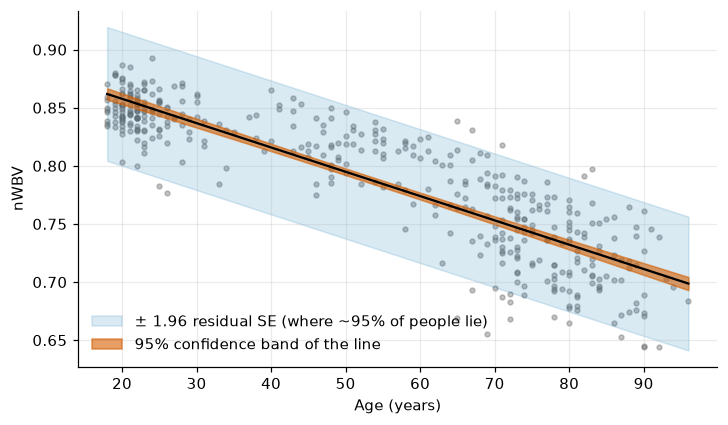

share of the participants inside the wide band: 0.950


In [17]:
xg = np.linspace(age.min(), age.max(), 200)
yg = a + b * xg
se_line = s_res * np.sqrt(1 / n + (xg - age.mean()) ** 2 / sxx)      # precision of the line

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(age, nwbv, s=10, color=GREY, alpha=.4)
ax.fill_between(xg, yg - 1.96 * s_res, yg + 1.96 * s_res, color=C1, alpha=.15,
                label="± 1.96 residual SE (where ~95% of people lie)")
ax.fill_between(xg, yg - t_crit * se_line, yg + t_crit * se_line, color=C2, alpha=.6,
                label="95% confidence band of the line")
ax.plot(xg, yg, color="black", lw=1.5)
ax.set_xlabel("Age (years)"); ax.set_ylabel("nWBV")
ax.legend(frameon=False, loc="lower left")
plt.show()

inside = (np.abs(resid) <= 1.96 * s_res).mean()
print(f"share of the participants inside the wide band: {inside:.3f}")

The orange confidence band is so narrow that it is hard to see: with 416 people, we know the line very precisely. The wide blue band contains about 95% of the dots, which is what the "1.96 standard deviations" statement in the slides describes. Be careful not to mix them up: the confidence interval concerns the *line* (it uses the standard error, which shrinks with the sample size), the wide band concerns *people* (it does not shrink with the sample size). It is the same distinction as between the SD and the SEM from week 3.

**Standardized slope (β).** The slope b depends on the scaling of the variables (years, nWBV units). To get a comparable value we z-standardize both variables *before* the regression. The slope of the z-standardized regression is called **β**. In simple regression, **β = r**.

In [18]:
beta = stats.linregress(zx, zy)
print(f"standardized slope beta = {beta.slope:.3f}   (r = {r_hand:.3f})")
print(f"intercept of the z-regression = {beta.intercept:.1e}   (the line goes through the means)")
print(f"-> 1 SD more age ({sx:.1f} years) goes along with {beta.slope:.2f} SD of nWBV ({beta.slope * sy:.4f} units)")

standardized slope beta = -0.873   (r = -0.873)
intercept of the z-regression = -2.2e-15   (the line goes through the means)
-> 1 SD more age (25.1 years) goes along with -0.87 SD of nWBV (-0.0525 units)


Reading: an age difference of one standard deviation (25 years) goes along with a brain volume difference of 0.87 standard deviations. In week 6 (multiple regression) we will compare several predictors, and β is what makes them comparable.

### 2.5 When can I use linear regression? Checking the assumptions

The assumptions are the same as for the correlation (equal-interval scale, linear relationship, homoscedasticity, normality), but for regression they are checked on the **residuals**:

1. **Linearity:** the residuals scatter randomly around 0, with no curve.
2. **Homoscedasticity:** the spread of the residuals is the same at all x.
3. **Normality of the residuals:** checked with the Q-Q plot, and with the quantitative tests from last week.

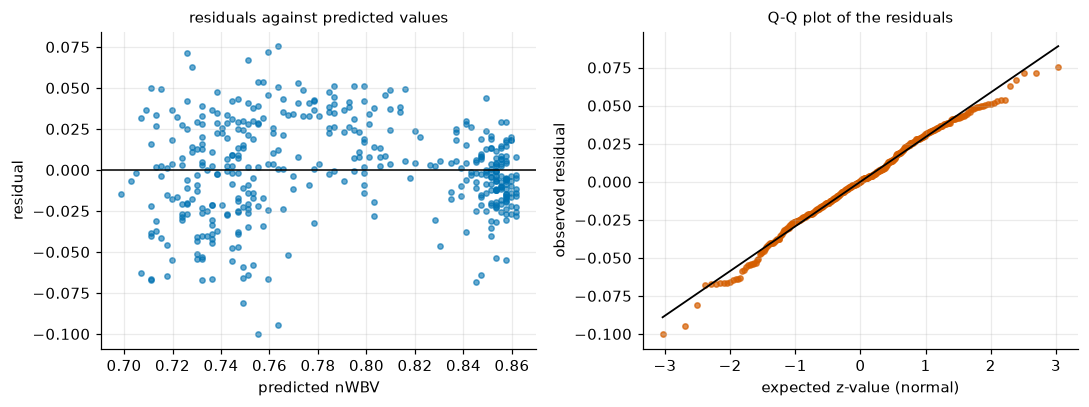

         n  SD of the residuals
18-39  156               0.0189
40-59   64               0.0209
60-79  135               0.0355
80+     61               0.0336


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(pred, resid, s=12, color=C1, alpha=.6)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("predicted nWBV"); axes[0].set_ylabel("residual")
axes[0].set_title("residuals against predicted values", fontsize=10)

res_sorted = np.sort(resid)
z_exp = stats.norm.ppf((np.arange(1, n + 1) - .5) / n)
axes[1].scatter(z_exp, res_sorted, s=12, color=C2, alpha=.7)
axes[1].plot(z_exp, resid.mean() + resid.std(ddof=1) * z_exp, color="black", lw=1.2)
axes[1].set_xlabel("expected z-value (normal)"); axes[1].set_ylabel("observed residual")
axes[1].set_title("Q-Q plot of the residuals", fontsize=10)
plt.tight_layout()
plt.show()

bands = pd.cut(age, [17, 40, 60, 80, 100], labels=["18-39", "40-59", "60-79", "80+"])
print(pd.DataFrame({"n": pd.Series(resid).groupby(bands, observed=True).size(),
                    "SD of the residuals": pd.Series(resid).groupby(bands, observed=True).std().round(4)}))

* **Linearity:** the left plot shows a *mild* curve: the residuals are mostly positive in the middle and negative at both ends. In the scatter plot this is visible too: among the young, brain volume is almost flat, and the decline gets steeper later. A straight line is a decent but not perfect summary (in real research we would try a curved term or an age-specific analysis).
* **Homoscedasticity:** the residuals fan out: young participants (high predicted nWBV, right side) are close to the line, older ones scatter more. The table confirms it: the SD of the residuals is about twice as large for the older groups (0.034 to 0.036) as for the young (0.019 to 0.021). This is a *moderate* violation, not as severe as with the MMSE in 1.5. It means that the line is a good average, but that its predictions are less precise for older people.
* **Normality:** the Q-Q plot follows the line except for deviations in the tails. Now the quantitative tests (same logic as last week: H0 = the residuals are normal; a small p means evidence against normality):

In [21]:
sw = stats.shapiro(resid)
dp = stats.normaltest(resid)
ad = stats.anderson(resid, dist="norm", method="interpolate")
print(f"Shapiro-Wilk       : W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}")
print(f"D'Agostino-Pearson : chi2 = {dp.statistic:.2f}, p = {dp.pvalue:.3f}")
print(f"Anderson-Darling   : A2 = {ad.statistic:.3f}, p = {ad.pvalue:.3f}")
print(f"skewness of the residuals = {stats.skew(resid):.2f}")

Shapiro-Wilk       : W = 0.992, p = 0.023
D'Agostino-Pearson : chi2 = 5.67, p = 0.059
Anderson-Darling   : A2 = 0.711, p = 0.066
skewness of the residuals = -0.28


The tests lie around the .05 line: Shapiro-Wilk rejects mildly (p ≈ .02), the other two do not quite (both p ≈ .06 to .07; the Anderson-Darling p-value of SciPy is interpolated). With n = 416 the tests are fairly sensitive, and the Q-Q plot shows only small deviations in the tails, so the departure from normality is mild. Together with the fact that a large sample makes the t-tests and confidence intervals of the regression fairly robust (central limit theorem), we would use the regression, but report the heteroscedasticity.

## 3. Does the picture change in a subgroup? The same analysis for participants with a CDR rating

At the end of section 2 we saw that a single straight line is not a perfect summary of the whole age range: the decline is flatter among the young and the spread of the residuals grows with age. One way to look at this is an **age-specific analysis**. The natural subgroup in OASIS is the set of participants with a **clinical dementia rating (CDR)**: it was only assessed in the older participants (n = 235). We repeat the steps of section 2 for this subgroup and compare the results with the whole sample.

Two cautions before we start. First, the subgroup is **part of** the whole sample, so the two analyses are not independent and we compare them *descriptively* (a significance test for the difference would need two separate groups). Second, the subgroup is not a random sample of the older population: it contains participants with and without dementia (CDR > 0 means demented).

### 3.1 Who is in the subgroup?

In [22]:
rated = df["CDR"].notna().to_numpy()
age_r, nwbv_r = age[rated], nwbv[rated]
cdr_r = df.loc[rated, "CDR"].to_numpy(float)

print(pd.DataFrame({
    "n": [n, rated.sum()],
    "Age: min": [age.min(), age_r.min()], "Age: max": [age.max(), age_r.max()],
    "Age: mean": [age.mean(), age_r.mean()], "Age: SD": [age.std(ddof=1), age_r.std(ddof=1)],
    "nWBV: SD": [nwbv.std(ddof=1), nwbv_r.std(ddof=1)]},
    index=["all participants", "with CDR rating"]).round(3))
print()
print("CDR ratings in the subgroup (0 = none, 0.5 = very mild, 1 = mild, 2 = moderate):")
print(pd.Series(cdr_r).value_counts().sort_index().to_string())

                    n  Age: min  Age: max  Age: mean  Age: SD  nWBV: SD
all participants  416      18.0      96.0     52.702   25.082     0.060
with CDR rating   235      33.0      96.0     72.345   12.091     0.048

CDR ratings in the subgroup (0 = none, 0.5 = very mild, 1 = mild, 2 = moderate):
0.0    135
0.5     70
1.0     28
2.0      2


The rated participants are all older than 32, the average age is 72, and, importantly, the **spread of age is only half as large** as in the whole sample (SD of 12 instead of 25 years). Keep this in mind: the correlation depends on how much the variables vary in the sample.

### 3.2 Correlation and regression in both samples

We run the steps of section 2 for both samples: the correlation, the least-squares line, R², the residual standard error, the standard error and the confidence interval of the slope, and the standardized slope β.

In [23]:
rows = {}
for name, x_, y_ in [("all participants", age, nwbv), ("with CDR rating", age_r, nwbv_r)]:
    n_ = len(x_)
    r_ = stats.pearsonr(x_, y_)[0]
    b_ = r_ * y_.std(ddof=1) / x_.std(ddof=1)
    a_ = y_.mean() - b_ * x_.mean()
    res_ = y_ - (a_ + b_ * x_)
    ss_res_, ss_tot_ = (res_ ** 2).sum(), ((y_ - y_.mean()) ** 2).sum()
    s_res_ = np.sqrt(ss_res_ / (n_ - 2))
    se_b_ = s_res_ / np.sqrt(((x_ - x_.mean()) ** 2).sum())
    tc = stats.t.ppf(.975, n_ - 2)
    rows[name] = {"n": n_, "r": r_, "R²": r_ ** 2, "intercept a": a_, "slope b": b_,
                  "SE of b": se_b_, "CI of b: lower": b_ - tc * se_b_, "CI of b: upper": b_ + tc * se_b_,
                  "beta": r_, "SS_tot": ss_tot_, "SS_res": ss_res_, "residual SE": s_res_}
comparison = pd.DataFrame(rows)
comparison.map(lambda v: f"{v:.0f}" if v == int(v) else (f"{v:.5f}" if abs(v) < .01 else f"{v:.3f}"))

,all participants,with CDR rating
n,416,235
r,-0.873,-0.720
R²,0.762,0.519
intercept a,0.900,0.956
slope b,-0.00209,-0.00285
SE of b,0.00006,0.00018
CI of b: lower,-0.00220,-0.00321
CI of b: upper,-0.00198,-0.00250
beta,-0.873,-0.720
SS_tot,1.499,0.537


Reading the table:

* **The slope is steeper in the rated participants** (−0.0029 per year instead of −0.0021, i.e. about −0.029 per decade). Between 33 and 96 years, the decline per year is faster than the average over the whole range 18 to 96 (which includes the almost flat young adults). The confidence intervals do not overlap.
* **r and R² are smaller** (r = −.72 and R² = .52, against −.87 and .76). Does this mean that age is a weaker predictor? Look at the **residual standard error**: it is almost the same (0.033 against 0.029). The line misses a typical person by about the same amount. What changed is the *total* variation, $SS_{tot}$, which is much smaller when we only look at older people: there is less variance to explain, so the share explained is smaller. This is the **restriction of range** effect: r and R² depend on how much x varies in the sample, even if the relationship itself is the same.
* **The intercept** (0.96) is even less interpretable than before: the line is now extrapolated far outside the data range (nobody here is younger than 33).

### 3.3 The two analyses side by side

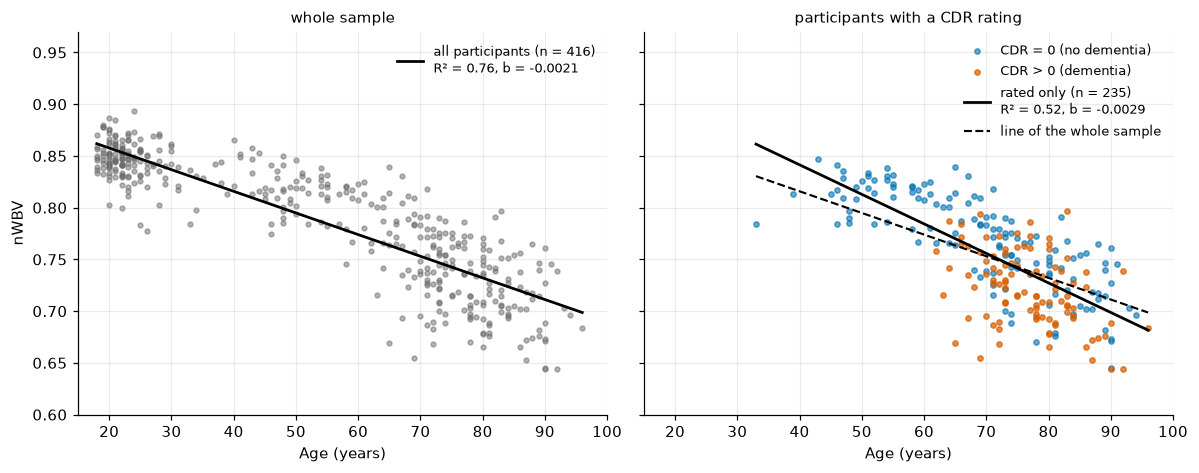

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
xx_all = np.array([age.min(), age.max()])
xx_r = np.array([age_r.min(), age_r.max()])
b_all, a_all = comparison.loc["slope b", "all participants"], comparison.loc["intercept a", "all participants"]
b_r, a_r = comparison.loc["slope b", "with CDR rating"], comparison.loc["intercept a", "with CDR rating"]

ax = axes[0]
ax.scatter(age, nwbv, s=10, color=GREY, alpha=.5)
ax.plot(xx_all, a_all + b_all * xx_all, color="black", lw=1.8,
        label=f"all participants (n = {n})\nR² = {comparison.loc['R²', 'all participants']:.2f}, b = {b_all:.4f}")
ax.set_title("whole sample", fontsize=10)

ax = axes[1]
dem = cdr_r > 0
ax.scatter(age_r[~dem], nwbv_r[~dem], s=12, color=C1, alpha=.6, label="CDR = 0 (no dementia)")
ax.scatter(age_r[dem], nwbv_r[dem], s=12, color=C2, alpha=.7, label="CDR > 0 (dementia)")
ax.plot(xx_r, a_r + b_r * xx_r, color="black", lw=1.8,
        label=f"rated only (n = {len(age_r)})\nR² = {comparison.loc['R²', 'with CDR rating']:.2f}, b = {b_r:.4f}")
ax.plot(xx_r, a_all + b_all * xx_r, color="black", lw=1.4, ls="--", label="line of the whole sample")
ax.set_title("participants with a CDR rating", fontsize=10)

for ax in axes:
    ax.set_xlabel("Age (years)"); ax.legend(frameon=False, fontsize=8.5, loc="upper right")
    ax.set_xlim(15, 100)
axes[0].set_ylabel("nWBV"); axes[0].set_ylim(0.6, 0.97)
plt.tight_layout()
plt.show()

The solid line in the right panel (rated participants) is steeper than the dashed line of the whole sample. The two colors show something new: the participants **with dementia** (orange) lie mostly in the lower half of the cloud. So within the rated group, brain volume depends not only on age but also on dementia status: a second predictor. That is the topic of the next session (multiple regression).

### 3.4 Assumptions in the subgroup

The same checks as in 2.5, on the residuals of the subgroup: is the spread of the residuals equal across ages (homoscedasticity), and are the residuals normal?

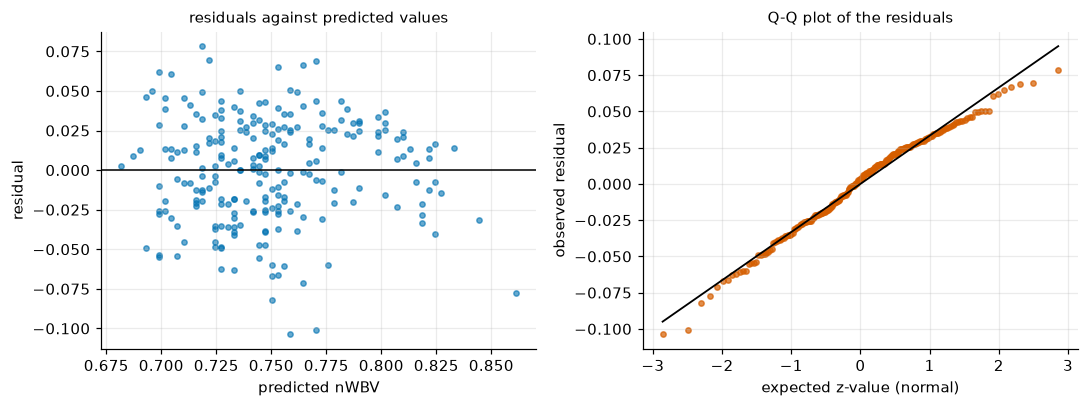

        n  SD of the residuals
33-69  84               0.0338
70-79  90               0.0322
80+    61               0.0336


,Shapiro-Wilk p,D'Agostino-Pearson p,Anderson-Darling p,skewness
all participants,0.023,0.059,0.066,-0.275
with CDR rating,0.039,0.091,0.022,-0.348


In [25]:
pred_r = a_r + b_r * age_r
resid_r = nwbv_r - pred_r

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(pred_r, resid_r, s=12, color=C1, alpha=.6)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("predicted nWBV"); axes[0].set_ylabel("residual")
axes[0].set_title("residuals against predicted values", fontsize=10)
n_r = len(resid_r)
z_exp_r = stats.norm.ppf((np.arange(1, n_r + 1) - .5) / n_r)
axes[1].scatter(z_exp_r, np.sort(resid_r), s=12, color=C2, alpha=.7)
axes[1].plot(z_exp_r, resid_r.mean() + resid_r.std(ddof=1) * z_exp_r, color="black", lw=1.2)
axes[1].set_xlabel("expected z-value (normal)"); axes[1].set_ylabel("observed residual")
axes[1].set_title("Q-Q plot of the residuals", fontsize=10)
plt.tight_layout()
plt.show()

bands_r = pd.cut(age_r, [32, 70, 80, 100], labels=["33-69", "70-79", "80+"])
print(pd.DataFrame({"n": pd.Series(resid_r).groupby(bands_r, observed=True).size(),
                    "SD of the residuals": pd.Series(resid_r).groupby(bands_r, observed=True).std().round(4)}))

tests = {}
for name, e in [("all participants", resid), ("with CDR rating", resid_r)]:
    tests[name] = {"Shapiro-Wilk p": stats.shapiro(e).pvalue, "D'Agostino-Pearson p": stats.normaltest(e).pvalue,
                   "Anderson-Darling p": stats.anderson(e, dist="norm", method="interpolate").pvalue,
                   "skewness": stats.skew(e)}
pd.DataFrame(tests).T.round(3)

* **Homoscedasticity:** in the subgroup the spread of the residuals is practically **equal across the age bands** (0.034, 0.032 and 0.034). The heteroscedasticity we saw in the whole sample (SD of 0.019 to 0.021 for the young against 0.034 to 0.036 for the old) was largely a result of mixing very different age ranges. Within the older participants, the assumption is fine.
* **Normality:** the Q-Q plot is close to the line, with a few low values in the left tail. The quantitative tests are, as in the whole sample, near the .05 line: the p-values are around .02 to .09, so the departure is again mild (a slight skew to the left: a few participants have a much lower brain volume than the line predicts).

**What did the subgroup analysis teach us?**

* The regression *slope* (−0.0029 per year) describes the decline in the older participants better than the whole-sample slope, which averages over a flat young and a steeper old range.
* R² and r are **not** properties of a relationship alone: they change with the range of the predictor. Compare slopes and residual standard errors, not only R², when the samples differ in their spread.
* A subgroup is selected, not random: the rated group contains participants with dementia, and dementia status explains additional variation in brain volume, which leads us to multiple regression next session.

## 4. Summary

* **Covariance** measures how two variables vary together, but depends on the units. **Pearson's r** = covariance / (s_x · s_y) = the covariance of the z-scores; it ranges from −1 to +1.
* **r²** is the shared variance. Age and `nWBV`: r = −.87, r² = .76.
* A correlation requires equal-interval data, a **linear** relationship and **equal spread** (homoscedasticity). Check the scatter plot; use rank correlations if the scale is ordinal.
* A correlation is tested with a **t-test** (df = N − 2). Correlations are compared with **Fisher's z-transformation** (not the z-standardization).
* **Correlation is not causation**, and our cross-sectional data compare different people, not one person over time.
* **Regression** predicts y from x with $y = a + b x$ by minimizing the **sum of squared residuals** (least squares). b is the change in y per unit of x; a is the value at x = 0 (often not interpretable); predict only within the range of the data.
* $R^2 = 1 - SS_{res}/SS_{tot}$; the slope has a standard error and a confidence interval, and its t-test equals the test of r. **β** (the slope of z-standardized variables) makes slopes comparable.
* Check the **residuals** for linearity, homoscedasticity and normality (plots and quantitative tests).

### Sources

* Slides: `05_CorrelationRegression.pptx` (course material).
* Data: Marcus, D. S., Wang, T. H., Parker, J., Csernansky, J. G., Morris, J. C., & Buckner, R. L. (2007). Open Access Series of Imaging Studies (OASIS): Cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. *Journal of Cognitive Neuroscience, 19*(9), 1498-1507.
* SciPy documentation: `scipy.stats` (`pearsonr`, `spearmanr`, `linregress`, `shapiro`, `normaltest`, `anderson`).